# Exercise 0 - PydanticAI and OpenRouter

In this exercise, you get to work with data validation using Pydantic v2 and PydanticAI. Output in general from LLMs are unstructured and hard to work with, to get any value from it you need to structure the output and validate its contents. This can be done with Pydantic.

## 0. Summarize job ads

In the data folder, there are a few job ads taken from arbetsförmedlingen.se.

### a) Read all the jobs ads into python



In [1]:
from pathlib import Path


def load_ads(data_dir: Path) -> dict[str, str]:
    """Read every job ad (ads*.txt) in a folder.

    Args:
        data_dir: Folder that contains the ads*.txt files.

    Returns:
        A dict mapping the file name without extension (e.g. "ads1")
        to the full text of that job ad.
    """
    ads = {}  # filled below: {"ads1": "<text>", "ads2": "<text>", ...}

    # sorted() keeps the order the same on every run (ads1, ads2, ads3)
    for file in sorted(data_dir.glob("ads*.txt")):
        # file.stem is the name without ".txt", so "ads1.txt" becomes "ads1"
        # encoding="utf-8" avoids garbled characters on Windows
        ads[file.stem] = file.read_text(encoding="utf-8")

    return ads


# ".." = go up one folder, from exercise_0/ to exercises/, then into data/
ads = load_ads(Path("..") / "data")

# Quick check that the files were read
for name, text in ads.items():
    print(name, "->", len(text), "characters")

ads1 -> 5519 characters
ads2 -> 7496 characters
ads3 -> 3968 characters
ads4 -> 3114 characters


### b) Create a function that uses PydanticAI agent to summarize a job ad. This function should take in an ad as its parameter and return a summary.

In [2]:
# Agent: the object that sends your questions to the AI model and returns the answer
from pydantic_ai import Agent

# OpenAIChatModel: a wrapper that talks to any service using OpenAI's chat format
from pydantic_ai.models.openai import OpenAIChatModel

# OpenAIProvider: holds the connection details (where to connect and how to log in)
from pydantic_ai.providers.openai import OpenAIProvider

import os  # lets us read environment variables

# It searches upward from the current folder, so it finds the .env in your project root.
# reads key=value pairs from a .env file
from dotenv import load_dotenv  


# NVIDIA's API speaks the same "chat completions" language as OpenAI,
# so we can reuse the OpenAI classes and just point them at NVIDIA's address.
model = OpenAIChatModel(
    "nvidia/nemotron-3.5-lightning-30b-a3b",  # the model name, same as lecture 01
    provider = OpenAIProvider(
        base_url="https://integrate.api.nvidia.com/v1",  # where to send requests
        api_key = os.environ["NVIDIA_API"], # key, read from .env (never hard-code it)
    ),
)

In [3]:
# The agent is the object that sends your prompt to the model and hands back the answer.
# `instructions` is the system prompt: it tells the model its job, every time it is called.
summary_agent = Agent(
    model,
    instructions = (
        "You are an assistant that summarizes job ads. "
        "Write a short clear summary in English covering the role, "
        "the main responsibilities and the key requirements."
    ),
)

async def summarize_ad(ad:str) -> str:
    """Summarize a single job ad.

    Args:
        ad: The full text of the job ad.

    Returns:
        A short summary written by the LLM.
    """
    # agent.run() sends the ad to the model as the user prompt and waits for the reply.
    # It is async, so we must `await` it. That works directly in a notebook cell.

    result = await summary_agent.run(ad, model_settings = {"timeout" : 120})

    # result.output is the model's answer in plain str
    return result.output

# Try in the first ad
summary = await summarize_ad(ads["ads1"])
print(summary)

                 pydantic-ai v2.62.0 • pydantic-ai-harness v0.62.0 • Python 3.13.7

      / \        agent: summary_agent • model: openai:nvidia/nemotron-3.5-lightning-30b-a3b
     /   \         tools: 0 • capabilities: 0
   /___.___\
  /    |    \    observability: off — see every model and tool call live, with cost
/      |      \    set it up free with Pydantic Logfire: uvx logfire-cli wizard --task pydantic-ai
`---.._|_..---'    or use any OpenTelemetry backend: https://pydantic.dev/docs/ai/logfire/#otel

                 goes away once observability is on — or PYDANTIC_AI_NO_BANNER=1


**Role:** Data Engineer & Analytics Engineer – shaping Instabee’s modern data platform on GCP and Snowflake to power BI, data science, and product-facing endpoints for stakeholders across the organization.

**Main Responsibilities:**
- Design and implement data integration patterns from diverse sources (APIs, MongoDB, MySQL) and build/maintain platform infrastructure on GCP/Snowflake
- Set up CI/CD pipelines and Infrastructure-as-Code; orchestrate workflows using Airflow or similar tools
- Model, transform, and govern data using DBT, SQL, and Python, ensuring discoverability, trustworthiness, and alignment with business processes
- Contribute to analytical projects that test hypotheses or solve stakeholder problems
- Collaborate with business, data, and tech teams to bridge gaps and communicate findings effectively

**Key Requirements:**
- University degree in a technical/analytical field (e.g., Computer Science, Mathematics, Physics)
- Proven experience spanning both Data Engineering 

- Agent(model, instructions=...): The agent wraps the model and adds the system prompt. Think of the system prompt as standing orders that apply to every call. The ad you pass in is the user prompt, the part that changes each time.

- async def and await: Talking to an LLM means waiting on the network. agent.run is async, so the function that calls it must also be async def and use await. In a normal .py script you would wrap the call in asyncio.run(...). In a notebook you can await directly. agent.run_sync also exists, but it often clashes with the notebook’s own event loop, so I’m avoiding it.

### c) Now create and export markdown files for each job ad and its corresponding summary.

In [4]:
# Folder for the generated files, next to the notebook: exercises/exercise_0/summaries/
output_dir = Path("summaries")

# parents/exist_ok: create the folder if missing, and don't error if it already exists
output_dir.mkdir(exist_ok=True)

async def export_summaries(ads:dict[str,str], output_dir:Path) -> None:
    """Summarize every ad and save ad + summary as one markdown file per ad.

    Args:
        ads: Mapping of ad name (e.g. "ads1") to the full ad text.
        output_dir: Folder where the .md files are written.
    """
    for name, ad in ads.items():
        # One LLM call per ad
        summary = await summarize_ad(ad)

        # Build the markdown text. "##" makes a heading.
        # The ad is placed under its own heading, followed by its summary.
        markdown = f"# {name}\n\n## Summary\n\n{summary}\n\n## Original ad\n\n{ad}\n"

        # Write it to e.g. summaries/ads1.md
        (output_dir / f"{name}.md").write_text(markdown, encoding="utf-8")
        print(f"Saved {name}.md")
await export_summaries(ads, output_dir)

Saved ads1.md
Saved ads2.md
Saved ads3.md
Saved ads4.md


- write_text(...) is the reverse of the read_text you used in 0a. It creates the file, or overwrites it if it exists. Use encoding="utf-8" here too, for the same reason as before.

- output_dir / f"{name}.md" uses the same / path-joining as before. The file name comes from the dict key, which is why we kept it.

- Sequential loop: The ads are summarized one after another, so three calls take roughly three times as long as one. That’s fine for three ads. If you had hundreds, you would run the calls concurrently with asyncio.gather

### d) Try to take other job ads from arbetsförmedlingen.se and see how well your function performs. (See ads4.txt)
- Go to arbetsförmedlingen and copy one job ad.

### e) Make the output structured using a pydantic model together with PydanticAI agent. The output from the agent should have the following fields:

- job_title
- description
- summary
- responsibilities
- words_in_article


In [5]:
from pydantic import BaseModel, Field

class JobAdSummary(BaseModel):
    """Structured summary of a job ad"""

    # Field(description=...) is not just documentation: PydanticAI sends these
    # descriptions to the LLM, so they act as per-field instructions.

    job_title: str = Field(description = "The title of the position")
    description: str = Field(description = "1-2 sentences about the company and the role")
    summary: str = Field("A short summary of the whole ad in English")
    responsibilities: str = Field("The main responsibilities, one short item per entry")
    words_in_article: str = Field("Number of words in the original job ad")

- BaseModel: Inheriting from it turns a plain class into a Pydantic model. Each line name: type declares a field and the type it must have.

- Types are rules: str means text, int means a whole number, and list[str] means a list of strings. If the LLM returns "about 300" for words_in_article, Pydantic rejects it. PydanticAI then sends the error back to the model and asks it to retry. That is the validation your exercise intro talks about.

- Field(description=...): Adds extra info to a field. Later you’ll also use it for constraints such as minimum and maximum values

In [6]:
extract_agent = Agent(
    model,
    output_type=JobAdSummary,  # the key change: the answer must fit this model
    instructions=(
        "You are an assistant that analyzes job ads. "
        "Fill in every field based only on the job ad. "
        "Write in English, even if parts of the ad are in Swedish."
    ),
)


async def extract_job_ad(ad: str) -> JobAdSummary:
    """Analyze a job ad and return it as a validated JobAdSummary.

    Args:
        ad: The full text of the job ad.

    Returns:
        A JobAdSummary object with all fields filled in and type-checked.
    """
    result = await extract_agent.run(ad, model_settings={"timeout": 120})
    # With output_type set, result.output is a JobAdSummary object, not a string
    return result.output


ad_info = await extract_job_ad(ads["ads4"])
print(ad_info.job_title)
print(ad_info.responsibilities)
print(ad_info.model_dump())  # the whole thing as a plain dict

Data Engineer
Design and operate data infrastructure (streaming and batch) and the systems that move data reliably at scale. Contribute to how events are defined, structured, and evolved across the platform. Ensure data quality, consistency, and observability across event pipelines. Ensure GDPR and PII compliance across data flows at scale. Contribute to data and architecture best practices that may span the whole organisation.
{'job_title': 'Data Engineer', 'description': 'Mentimeter AB, a fast‑growing edtech company, seeks a Data Engineer to design and operate an event‑driven data platform that powers analytics, growth, personalization and decision‑making across the organisation.', 'summary': 'Mentimeter is hiring a Data Engineer to build and maintain scalable streaming and batch data infrastructure, ensure data quality and GDPR compliance, and shape a new event‑driven architecture in a hybrid role based in Stockholm.', 'responsibilities': 'Design and operate data infrastructure (str

In [7]:
print("LLM says:   ", ad_info.words_in_article)
print("Actually is:", len(ads["ads4"].split()))

LLM says:    447
Actually is: 449


## 1. Product extractor

In this task you will based on product descriptions, be able to extract out relevant information into structured format using pydantic model together with PydanticAI agent.

### a) Read the `products.json` and store all of its descriptions into a list

In [8]:
import json

def load_products(path:Path) -> list[dict]:
    """Read the product list from a JSON file.

    Args:
        path: Path to products.json.

    Returns:
        A list of dicts, one per product, with keys such as
        id, name, price, category, in_stock and description.
    """
    # json.load() parses the JSON text from the file into Python lists and dicts
    with open(path, encoding="utf-8") as f:
        return json.load(f)


products = load_products(Path("..")/"data"/"products.json")

# What the exercise asks for: all the descriptions in a list
descriptions = [product["description"]for product in products]

print(len(descriptions), "descriptions")
print(descriptions[0])


10 descriptions
The Nike Running Shoes X90 are available for $120.00 in the Footwear section.


- json.load(f) reads a JSON file and turns it into Python objects. JSON arrays become lists, JSON objects become dicts, true becomes True, and numbers become int or float. You don’t parse anything by hand.

- [product["description"] for product in products] is the list comprehension from 0a again. It means “take the description key from each product dict”.

### b) Loop through this list and extract structured output from each of the descriptions. The structure should have the fields: name, price, category, in_stock and description

In [9]:
# The Model
class ProductInfo(BaseModel):
    """Structured product data extracted from a free-text description."""

    name:str = Field(description = "The product's name")
    price:float = Field(ge=0, description= "Price as a number without the currency symbol")
    category:str = Field(description="Product cateogry")
    in_stock:bool = Field(description= "True if the product is availablen now.")
    description: str = Field(description= "A short one sentence description of the product")

In [10]:
# The Agent 
product_agent = Agent(
    model,
    output_type = ProductInfo, #the output must fit Product Info Model from Pydantic
    instructions = (
        "Extract structured product information from a product description."
        "Use only what the description says. Do not invent anything or hallucinate."
    ),
)

# The Loop
async def extract_product(text: str) -> ProductInfo:
    """Extract a ProductInfo from one product description.

    Args:
        text: A free-text product description.

    Returns:
        A validated ProductInfo object.
    """

    result = await product_agent.run(text, model_settings = {"timeout": 120})
    return result.output


# One call per description. Results keep the same order as `descriptions`,
# so extracted[i] belongs to products[i]. We rely on that in step 1c.
extracted = []
for text in descriptions:
    info = await extract_product(text)
    extracted.append(info)
    print(info.name, "|", info.price, "|", info.category, "|", info.in_stock)


Nike Running Shoes X90 | 120.0 | Footwear | True
Sony WH-1000XM5 Headphones | 349.99 | Electronics | True
Dyson V12 Vacuum Cleaner | 599.99 | Home & Garden | False
Adidas Ultraboost 22 Sneakers | 189.95 | Footwear | True
Apple iPad Pro 11-inch | 799.0 | Electronics | True
Levi's 501 Original Jeans | 69.5 | Clothing | True
Bosch Cordless Drill GSR18 | 149.0 | Automotive | False
Canon EOS R50 Camera | 679.99 | Electronics | True
Philips Air Purifier 3000i | 299.95 | Home & Garden | True
Samsung Galaxy Watch 6 | 299.0 | Electronics | False


### c) Now try to validate programmatically if the output fields are correct.
- Fields with a single right answer: name, price, category, in_stock. You compare them to the ground truth in products.json, using plain Python. 

In [11]:
# Check 1: Compare the exact fields
import math
import pandas as pd

def check_product(expected: dict, actual:ProductInfo) -> dict[str, bool]:
    """Compare an extracted product with the known correct values.

    Args:
        expected: The original product dict from products.json (the ground truth).
        actual: What the agent extracted from the description.

    Returns:
        A dict saying, per field, whether the extracted value is correct.
    """
    return {
        # strip() and lower() ignore stray spaces and capitalization differences
        "name": actual.name.strip().lower() == expected["name"].strip().lower(),
        # Never compare floats with ==. Allow a tiny tolerance instead.
        "price": math.isclose(actual.price, expected["price"], abs_tol=0.01),
        "category": actual.category.strip().lower() == expected["category"].strip().lower(),
        "in_stock": actual.in_stock == expected["in_stock"],
    }


# zip pairs the answer key with the extraction in the same position.
# This is why we kept the order the same in 1b.
checks = [check_product(p, e) for p, e in zip(products, extracted)]

# A table with one row per product and one True/False column per field
results = pd.DataFrame(checks)
print(results)


   name  price  category  in_stock
0  True   True      True      True
1  True   True      True      True
2  True   True      True      True
3  True   True      True      True
4  True   True      True      True
5  True   True      True      True
6  True   True      True      True
7  True   True      True      True
8  True   True      True      True
9  True   True      True      True


In [12]:
# Show every product that has at least one wrong field
for product, info, check in zip(products, extracted, checks):
    if not all(check.values()):
        print(product["description"])
        print("  expected:", {k: product[k] for k in check})
        print("  got:     ", info.model_dump(include=set(check)))
        print()

## 2. Sentiment analysis

You will use agent here to determine if a review is positive, negative or neutral for a set of reviews.

### a) Read in `reviews.json` and extract all texts and store it in a list


In [13]:
reviews = load_products(Path("..")/"data"/"reviews.json")

review_texts = [review["text"] for review in reviews]

print(len(review_texts), "reviews")
print(review_texts[0])

12 reviews
I absolutely loved this damn product! Worst purchase I have made all year. The quality is outstanding and delivery was super slow.


### b) Iterate your list and use an agent to give a sentiment.

In [14]:
# the model
from typing import Literal

class SentimentResult(BaseModel):
    """Sentiment classification of a single review"""
    # Literal restricts the value to exactly these three strings.
    # Unlike a plain `str`, the LLM can't return "mixed" or "Positive" (capitalized) and pass.
    sentiment: Literal["positive", "negative", "neutral"] = Field(
        description = "Overall sentiment of the review: positive, negative or neutral"
    )

# the agent
sentiment_agent = Agent(
    model,
    output_type = SentimentResult,
    instructions = (
        "You classify the sentiment of a product review as exactly one of: "
        "positive, negative or neutral. "
        "If the review has both good and bad points that roughly balance out, "
        "or is mostly factual with no strong opinion, classify it as neutral."
    ),
)

# the loop
async def classify_sentiment(text: str) -> str:
    """Classify a review's sentiment.

    Args:
        text: The review text.

    Returns:
        One of "positive", "negative", "neutral".
    """
    result = await sentiment_agent.run(text, model_settings={"timeout": 120})
    return result.output.sentiment

# One call per review, same order as review_texts, so predictions[i] matches reviews[i]
predictions = []
for text in review_texts:
    pred = await classify_sentiment(text)
    predictions.append(pred)
    print(pred, "|", text[:60])


neutral | I absolutely loved this damn product! Worst purchase I have 
negative | Terrible experience. The item arrived broken and customer su
neutral | It is okay. Does what it says on the box, nothing more nothi
positive | Absolutely fantastic! Exceeded all my expectations. The desi
negative | Disappointed. The color looked different in the photos and t
neutral | Received the order on time. Product matches the description.
positive | Five stars without hesitation! This has completely changed m
negative | Worst product I have ever bought. Stopped working after thre
neutral | Shipping took longer than expected but the product itself is
positive | Amazing build quality and the customer service team was incr
negative | Package arrived damaged and the product inside was scratched
positive | It works as described. Setup was straightforward and I have 


> For the tasks below, remember what you've learnt from classical machine learning on how to validate prediction against ground truth. Note that here you might need to calculate them yourself.

### c) Now validate how many correct you got and compute the accuracy.

In [15]:
expected = [review["expected_sentiment"] for review in reviews]

# Pair up each review's expected label and predicted label, in order
for review, exp, pred in zip(reviews, expected, predictions):
    match = "✓" if exp == pred else "✗"
    print(f"{match} expected={exp:<8} predicted={pred:<8} {review['text'][:50]}")

# Accuracy = number of correct predictions / total predictions
correct = sum(1 for exp, pred in zip(expected, predictions) if exp == pred)
accuracy = correct / len(expected)

print(f"\n{correct}/{len(expected)} correct")
print(f"Accuracy: {accuracy:.2%}")

✓ expected=neutral  predicted=neutral  I absolutely loved this damn product! Worst purcha
✓ expected=negative predicted=negative Terrible experience. The item arrived broken and c
✗ expected=positive predicted=neutral  It is okay. Does what it says on the box, nothing 
✓ expected=positive predicted=positive Absolutely fantastic! Exceeded all my expectations
✓ expected=negative predicted=negative Disappointed. The color looked different in the ph
✓ expected=neutral  predicted=neutral  Received the order on time. Product matches the de
✓ expected=positive predicted=positive Five stars without hesitation! This has completely
✓ expected=negative predicted=negative Worst product I have ever bought. Stopped working 
✓ expected=neutral  predicted=neutral  Shipping took longer than expected but the product
✓ expected=positive predicted=positive Amazing build quality and the customer service tea
✓ expected=negative predicted=negative Package arrived damaged and the product inside was
✗ expected

### d) Also compute recall and precision. Precision and recall

 These are usually taught for two classes, but you have three (positive, negative, neutral), so we compute them per class, treating each one in turn as “the class we care about” versus “everything else.”

The idea first

For a given class, say positive:

- True positive (TP): predicted positive, and it actually is positive.
- False positive (FP): predicted positive, but it’s actually something else.
- False negative (FN): predicted something else, but it’s actually positive.

Then:

- Precision = TP / (TP + FP) — of everything you labeled positive, how much actually was?
- Recall = TP / (TP + FN) — of everything that actually was positive, how much did you catch?

In [16]:
labels = ["positive", "negative", "neutral"]


def precision_recall(label: str, expected: list[str], predictions: list[str]) -> tuple[float, float]:
    """Compute precision and recall for one class, treating it as positive vs. the rest.

    Args:
        label: The class to evaluate, e.g. "positive".
        expected: Ground-truth labels.
        predictions: Model's predicted labels, same order as expected.

    Returns:
        (precision, recall) for this class.
    """
    tp = sum(1 for e, p in zip(expected, predictions) if p == label and e == label)
    fp = sum(1 for e, p in zip(expected, predictions) if p == label and e != label)
    fn = sum(1 for e, p in zip(expected, predictions) if p != label and e == label)

    # Guard against dividing by zero, e.g. if the model never predicted this label
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    return precision, recall


for label in labels:
    precision, recall = precision_recall(label, expected, predictions)
    print(f"{label:<8} precision={precision:.2f}  recall={recall:.2f}")

# Macro average: the simple average across the three classes.
# Treats every class equally, regardless of how many reviews belong to it.
precisions, recalls = zip(*(precision_recall(l, expected, predictions) for l in labels))
print(f"\nMacro precision: {sum(precisions)/len(precisions):.2f}")
print(f"Macro recall:    {sum(recalls)/len(recalls):.2f}")

positive precision=0.75  recall=0.75
negative precision=1.00  recall=1.00
neutral  precision=0.75  recall=0.75

Macro precision: 0.83
Macro recall:    0.83


### e) Create a confusion matrix.

In [17]:
# A table with one row per review: its actual and predicted label
df = pd.DataFrame({"actual": expected, "predicted": predictions})

# crosstab counts how many rows fall into each (actual, predicted) combination.
# reindex forces the row/column order to be positive, negative, neutral even if
# one of them never appears, and fills missing combinations with 0 instead of NaN.
confusion = pd.crosstab(df["actual"], df["predicted"]).reindex(
    index=labels, columns=labels, fill_value=0
)

print(confusion)

predicted  positive  negative  neutral
actual                                
positive          3         0        1
negative          0         4        0
neutral           1         0        3


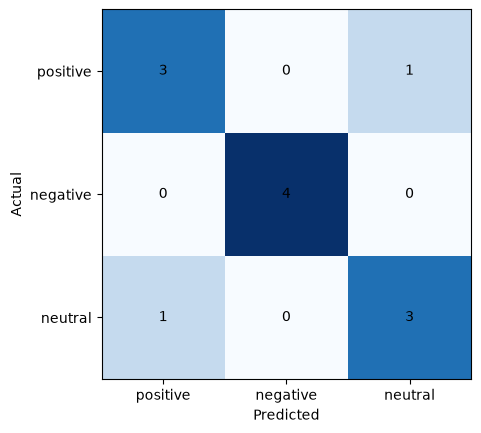

In [18]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.imshow(confusion, cmap="Blues")
ax.set_xticks(range(len(labels)), labels)
ax.set_yticks(range(len(labels)), labels)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, confusion.iloc[i, j], ha="center", va="center")
plt.show()

## 3. A grading assistant

Teachers in general have a lot of administrations to do and one of those things is grading. Can we create a simple grade assistant to assist a Swedish teacher in grading? This exercise focuses a lot in prompt engineering and afterwards to postprocess the output using Pydantic.

> [!NOTE]
> this task is easier if you know Swedish. If you don't know Swedish you could adapt it to other language, but need to find other data, or you could use LLM to translate the data into English.

### a) [Go into this page with examples of students answers](https://www.uu.se/download/18.11971c6f1989761a6625867/1755009079925/Svsva%20Niv%C3%A5%201%20Del%20C%20Resonerande%20uppgift,%20matris,%20analys.pdf) to a particular question. Copy some example texts and paste it into files with names like `student_text_1.txt`, `student_text_2.txt`.


In [19]:
### b) Read these data into python and tell your LLM to grade them.
# reuses 0a's loader; it globs any "student_text*.txt" too
student_texts = load_ads(Path("..")/"data")

def load_texts(data_dir:Path, pattern: str) -> dict[str, str]:
    """Read every text file matching a glob pattern into a dict.

    Args:
        data_dir: Folder to search in.
        pattern: Glob pattern, e.g. "student_text*.txt".

    Returns:
        Dict mapping file stem (e.g. "student_text_1") to its text.
    """
    return {f.stem: f.read_text(encoding="utf-8") for f in sorted(data_dir.glob(pattern))}

student_texts = load_texts(Path("..")/"data", "student_text*.txt")
print(list(student_texts))

['student_text_1', 'student_text_2']


In [20]:
# An agent that grades
grading_agent = Agent(
    model,
    instructions=(
        "You are a Swedish language teacher grading a student's written response "
        "to a reasoning task (resonerande uppgift) for the course Svenska 1. "
        "Give a grade (E, D, C, B or A), a short motivation for the grade, "
        "and concrete suggestions for improvement. Respond in Swedish."
    ),
)

async def grade_text(text: str) -> str:
    """Ask the LLM to grade one student's text.

    Args:
        text: The student's written answer.

    Returns:
        The LLM's plain-text grading response.
    """
    result = await grading_agent.run(text, model_settings = {"timeout": 120})
    return result.output

for name, text in student_texts.items():
    grading = await grade_text(text)
    print(f"--- {name} ---")
    print(grading)
    print()

--- student_text_1 ---
**Betyg: C**

**Motivation:** Eleven uppfyller grundkraven för Svenska 1 genom att tydliggöra uppgiften, presentera en egen inställning och referera till Peter Letmarks artikel. Innehållet är förståeligt och texten har en inledning, en påståendepart och ett avslut med förslag till lösning. Språket når fram med budskapet, men det finns flera grammatiska fel och formuleringar som tyder på att svenska fortfarande befinner sig på en basnivå. Exempel på fel som påverkar betyget: „det vanligast rädslan“ ska vara „den vanligaste rädslan“, uttrycket „ta plast“ är osäkert och syftet medses inte fullt ut, och meningarna ibland blir klumpiga på grund av fel på bestämda/obestämda former, böjningsfel och obekväma prepositioner. Eleven når fram, men saknar felfrihet och språklig variation för ett högre betyg.

**Förslag till förbättring:**
1. **Grammatik och böjningsformer:** Gena igenom användningen av bestämda artiklar (t.ex. *den/det/denna* vs obestämd *en/ett*) och verb ef

### c) Make structured output with fields proposed_grade, motivation and improvements.

In [22]:
class GradingResult(BaseModel):
    """Structured grading of a student's text."""

    # Literal locks the grade to exactly the Swedish grading scale.
    # Order matters only for readability here; Literal doesn't treat them as ranked.
    proposed_grade: Literal["F", "E", "D", "C", "B", "A"] = Field(
        description="The proposed grade on the Swedish scale F (fail) to A (highest)"
    )
    motivation: str = Field(description="A short explanation of why this grade was given")
    improvements: list[str] = Field(
        description="Concrete, actionable suggestions for how the student could improve"
    )


grading_agent = Agent(
    model,
    output_type=GradingResult,
    instructions=(
        "You are a Swedish language teacher grading a student's written response "
        "to a reasoning task (resonerande uppgift) for the course Svenska 1. "
        "Write the motivation and improvements in Swedish."
    ),
)


async def grade_text(text: str) -> GradingResult:
    """Grade a student's text and return a structured result.

    Args:
        text: The student's written answer.

    Returns:
        A validated GradingResult.
    """
    result = await grading_agent.run(text, model_settings={"timeout": 120})
    return result.output


grades = {}
for name, text in student_texts.items():
    grades[name] = await grade_text(text)
    print(name, "->", grades[name].proposed_grade)

student_text_1 -> C
student_text_2 -> C


### d) Output a folder with the following txt files: proposed_grade.txt, motivation.txt and improvements.txt

In [23]:
def export_grading(name: str, grading: GradingResult, output_dir: Path) -> None:
    """Write one student's grading as three separate text files.

    Args:
        name: Student identifier, e.g. "student_text_1". Used as the subfolder name.
        grading: The structured grading result for this student.
        output_dir: Base folder; a subfolder named `name` is created inside it.
    """
    student_dir = output_dir / name
    student_dir.mkdir(parents=True, exist_ok=True)

    (student_dir / "proposed_grade.txt").write_text(grading.proposed_grade, encoding="utf-8")
    (student_dir / "motivation.txt").write_text(grading.motivation, encoding="utf-8")

    # improvements is a list[str]; join with newlines so each suggestion is its own line
    (student_dir / "improvements.txt").write_text(
        "\n".join(grading.improvements), encoding="utf-8"
    )
    print(f"Saved files to {student_dir}")


grading_output_dir = Path("grading_output")
for name, grading in grades.items():
    export_grading(name, grading, grading_output_dir)

Saved files to grading_output\student_text_1
Saved files to grading_output\student_text_2


### e) In the data folder there is a file called svenska1_criterias.txt and copy "Betygskriterier" for "Svenska 1". These are the criterias for the different grades. Read these into Python and use them for f).

In [24]:
def load_criteria(path: Path) -> str:
    """Read the grading criteria text, keeping only the "Betygskriterier" section onward.

    Args:
        path: Path to svenska1_criterias.txt.

    Returns:
        The criteria section as plain text (everything from "Betygskriterier" to the end).
    """
    full_text = path.read_text(encoding="utf-8")

    # split on the heading and take the half of the text that comes after it
    _, criteria = full_text.split("Betygskriterier", 1)
    return "Betygskriterier" + criteria  # keep the heading itself for context


criteria_text = load_criteria(Path("..") / "data" / "svenska1_criterias.txt")
print(criteria_text)

Betygskriterier
Betyget E
Eleven kan, i förberedda samtal och diskussioner, muntligt förmedla egna tankar och åsikter samt genomföra muntlig framställning inför en grupp. Detta gör eleven med viss säkerhet. Den muntliga framställningen är sammanhängande och begriplig. Eleven har viss åhörarkontakt. Språket är till viss del anpassat till syfte, mottagare och kommunikations­situation. Vidare kan eleven med viss säkerhet använda presentationstekniska hjälpmedel.

Eleven kan skriva argumenterande text och andra typer av texter, som är sammanhängande och begripliga samt till viss del anpassade till syfte, mottagare och kommunikations­situation. Eleven kan i huvudsak följa skriftspråkets normer för språkriktighet.

Eleven kan läsa, reflektera över och göra enkla sammanfattningar av texter samt skriva egna texter som anknyter till det lästa. I sitt arbete värderar och granskar eleven med viss säkerhet källor kritiskt samt tillämpar grundläggande regler för citat- och referatteknik.

Eleven ka

### f) Now repeat b)-e) but with the criterias in your prompt as well. Can you see any differences in the outputs?

In [25]:
# f-string lets us drop criteria_text straight into the instructions text
grading_agent_with_criteria = Agent(
    model,
    output_type=GradingResult,
    instructions=(
        "You are a Swedish language teacher grading a student's written response "
        "to a reasoning task (resonerande uppgift) for the course Svenska 1. "
        "Base your grade strictly on the official grading criteria below. "
        "Write the motivation and improvements in Swedish, and in the motivation "
        "refer to which criteria the text does and does not meet.\n\n"
        f"{criteria_text}"
    ),
)


async def grade_text_with_criteria(text: str) -> GradingResult:
    """Grade a student's text against the official criteria.

    Args:
        text: The student's written answer.

    Returns:
        A validated GradingResult, grounded in svenska1_criterias.txt.
    """
    result = await grading_agent_with_criteria.run(text, model_settings={"timeout": 120})
    return result.output


grades_with_criteria = {}
for name, text in student_texts.items():
    grades_with_criteria[name] = await grade_text_with_criteria(text)
    print(name, "->", grades_with_criteria[name].proposed_grade)

student_text_1 -> C
student_text_2 -> D


In [26]:
grading_output_with_criteria_dir = Path("grading_output_with_criteria")
for name, grading in grades_with_criteria.items():
    export_grading(name, grading, grading_output_with_criteria_dir)

Saved files to grading_output_with_criteria\student_text_1
Saved files to grading_output_with_criteria\student_text_2


In [27]:
for name in student_texts:
    print(f"=== {name} ===")
    print("without criteria:", grades[name].proposed_grade, "-", grades[name].motivation)
    print("with criteria:   ", grades_with_criteria[name].proposed_grade, "-", grades_with_criteria[name].motivation)
    print()

=== student_text_1 ===
without criteria: C - Eleven visar tydlig förståelse för ämnet och kan presentera egna åsikter om talsfobi och artikeln av Peter Letmark. Texten har en genomgripen struktur och nyckelbegrepp används korrekt. Det finns dock flera grammatiska fel, stavfel och ordfel som påverkar läsbarheten och kravet på korrekt svenska i Svenska 1.
with criteria:    C - Texten uppfyller kraven för betyget C i huvudsak. Den är sammanhängande och begriplig, och syfte med uppgiften (att resonera kring rädslan för muntliga presentationer) är tydligt. Dispositionen är tydligt urskiljbar med en inledning, en del där textens innehåll och ett avslut. Eleven reflekterar över den lästa artikeln av Peter Letmark och använder innehållet för att stödja egna åsikter, vilket uppfyller kravet på att skriva egna texter som anknyter till det lästa och visar viss säkerhet när man värderar och granskar källor kritiskt samt applicerar grundläggande referatteknik. Språket är till stor del anpassat till

### g) Can you improve the output quality by providing few shot examples?

In [28]:
# A short, hand-written example, independent of your two real students, so neither
# student_text_1 nor student_text_2 doubles as both "example" and "thing being graded".
few_shot_example = """
Exempel på elevtext:
"Jag tycker muntliga presentationer är läskiga men man blir bättre om man övar.
Man kan använda bilder för att göra det lättare. Det är viktigt att prata tydligt."

Exempel på bedömning:
proposed_grade: E
motivation: Texten tar upp ett relevant perspektiv men är kort och saknar fördjupning.
Resonemanget är enkelt och underbyggs inte med exempel eller motargument, vilket gör
att den uppfyller kriterierna för E men inte D.
improvements:
- Utveckla resonemanget med fler exempel.
- Lyft fram och bemöt motargument.
- Använd ett mer varierat språk.
"""

In [29]:
grading_agent_few_shot = Agent(
    model,
    output_type=GradingResult,
    instructions=(
        "You are a Swedish language teacher grading a student's written response "
        "to a reasoning task (resonerande uppgift) for the course Svenska 1. "
        "Base your grade strictly on the official grading criteria below. "
        "Write the motivation and improvements in Swedish, and in the motivation "
        "refer to which criteria the text does and does not meet.\n\n"
        f"{criteria_text}\n\n"
        "Here is one worked example of the grading style expected:\n"
        f"{few_shot_example}"
    ),
)


async def grade_text_few_shot(text: str) -> GradingResult:
    """Grade a student's text, guided by criteria and one worked example.

    Args:
        text: The student's written answer.

    Returns:
        A validated GradingResult.
    """
    result = await grading_agent_few_shot.run(text, model_settings={"timeout": 120})
    return result.output


grades_few_shot = {}
for name, text in student_texts.items():
    grades_few_shot[name] = await grade_text_few_shot(text)
    print(name, "->", grades_few_shot[name].proposed_grade)

student_text_1 -> C
student_text_2 -> C


In [30]:
for name in student_texts:
    print(f"=== {name} ===")
    print("no criteria:        ", grades[name].proposed_grade)
    print("with criteria:      ", grades_with_criteria[name].proposed_grade)
    print("criteria + few-shot:", grades_few_shot[name].proposed_grade)
    print("motivation:", grades_few_shot[name].motivation)
    print()

=== student_text_1 ===
no criteria:         C
with criteria:       C
criteria + few-shot: C
motivation: Texten är sammanhängande och begriplig, och syfte samt mottagare är tydliga. Eleven redogör för sina egna erfarenheter av muntliga presentationer och använder artikeln av Peter Letmark i DN som utgångspunkt för resonemanget. Eleven kan sammanfatta huvudtanken i den lästa artikeln och reflektera över sambandet mellan rädslan att tala och evolutionär utveckling. Dispositionen i den skriftliga framställningen är tydligt urskiljbar (inledning, egen erfarenhet,Referat av artikel, förslag på övning). Språket är till största del korrekt men det finns mindre felaktigheter till exempel 'den vanligast rädslan' och uttrycken är något enformiga, vilket hindrar att texten når nivån B. Eleven uppfyller därmed kraven för betyget C enligt de formulerade kriterierna: kan skriva argumenterande text som är anpassad till syfte, mottagare och kommunikationssituation; dispositionen är tydlig; eleven refle